# Member 2 — Notebook 2: Use the Saved Forecasting Engine

**Project:** J26-DS-322 — Data-Driven Decision Support System to Mitigate the Cobweb Effect in Sri Lankan Vegetable Markets  
**Student:** Garusingarachchi Y.B. — IT23415836  
**Component:** Hybrid Temporal Forecasting Engine

This notebook runs **after Notebook 1**.

It does **not train or refit any model**. The saved tree artifacts use an internal 2022 early-stopping slice, are refit on all eligible pre-2023 training rows, calibrated on untouched 2023 observations, and tested on 2024–2025.

It uses the artifacts already saved by Notebook 1 to:

- read the final A/B and B*/C evaluation results;
- reproduce saved Experiment B and Experiment C forecasts;
- demonstrate the real **dynamic cultivation-update re-forecasting experiment** for the same future target using successive real cultivation-information states;
- create a 12-series one-week C forecast batch for the four headline markets;
- create a downstream packet for Member 3;
- write compact JSON files for Member 4 / the studio;
- save a Notebook 2 manifest.

### Locked interpretation

- **A:** price lags + seasonality
- **B:** A + supply-origin weather + macroeconomic variables + finished-season historical extent
- **B\*:** B retrained on exactly the rows eligible for real Experiment C
- **C:** B + real **national within-season cultivation progress**
- C uses exact-season, as-of information only.
- District cultivation rows are audit/descriptive evidence only.
- The reported B*→C result is empirical; C is **not assumed** to improve every horizon.
- `coverage_level = 0.90` means the intended interval level. The measured held-out PICP is reported separately.

**Important:** Notebook 2 never calls any fitting function.


## Cell 2 — Mount Drive and verify Notebook 1 artifacts

This cell only checks that the completed Notebook 1 artifacts exist. It installs model libraries only so the saved `joblib` bundles can be loaded.


In [1]:
from google.colab import drive
from pathlib import Path
import json
import subprocess
import sys

import pandas as pd
import numpy as np

drive.mount("/content/drive")

DRIVE = Path("/content/drive/MyDrive/DS322-member2")
NB1 = DRIVE / "01_from_notebook1"
NB2 = DRIVE / "02_from_notebook2"

if not DRIVE.is_dir():
    raise SystemExit(f"Missing Drive project folder: {DRIVE}")

for folder in [
    "inference",
    "studio_json",
    "runtime_demo",
]:
    (NB2 / folder).mkdir(parents=True, exist_ok=True)

# Needed only to unpickle / execute the already-fitted model bundles.
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "lightgbm",
    "xgboost",
    "joblib",
    "pyarrow",
])

required = [
    "experiment_b/predictions.csv",
    "experiment_b/metrics_with_cqr.csv",
    "experiment_b/cqr.json",
    "experiment_b/live_vectors.json",
    "experiment_b/models/lightgbm_B_h1_q05.joblib",
    "experiment_b/models/lightgbm_B_h1_q50.joblib",
    "experiment_b/models/lightgbm_B_h1_q95.joblib",
    "experiment_b/models/training_protocol.json",
    "experiment_c/status.json",
    "experiment_c/b_star_vs_c.csv",
    "experiment_c/metrics_b_star.csv",
    "experiment_c/metrics_c.csv",
    "experiment_c/cqr.json",
    "experiment_c/predictions_b_star.csv",
    "experiment_c/predictions_c.csv",
    "experiment_c/live_vectors.json",
    "experiment_c/c_eligible_table.parquet",
    "experiment_c/models/lightgbm_C_h1_q05.joblib",
    "experiment_c/models/lightgbm_C_h1_q50.joblib",
    "experiment_c/models/lightgbm_C_h1_q95.joblib",
    "experiment_c/models/training_protocol.json",
    "experiment_c/models_b_star/training_protocol.json",
    "notes/validation_protocol.json",
    "evaluation/final_point_forecast_benchmark.csv",
    "evaluation/best_point_model_by_horizon.csv",
    "evaluation/seasonal_naive_common_subset.csv",
    "evaluation/mase_scale_52w_by_series.csv",
    "evaluation/model_vs_naive_block_bootstrap.csv",
    "evaluation/final_probabilistic_evaluation_c.csv",
    "evaluation/quantile_crossing_diagnostic_c.csv",
    "evaluation/conditional_interval_evaluation_c.csv",
    "audit/doa_source_vs_observation_season_mismatch.csv",
    "evaluation/feature_set_evolution.csv",
    "evaluation/bstar_vs_c_block_bootstrap.csv",
    "evaluation/robustness_c_h4_by_crop.csv",
    "evaluation/robustness_c_h4_by_market.csv",
    "evaluation/robustness_c_h4_by_season.csv",
    "evaluation/robustness_c_h4_shock_vs_nonshock.csv",
    "evaluation/robustness_b_h4_shock_vs_nonshock.csv",
    "evaluation/residual_summary_c_h4.csv",
    "evaluation/shap_lightgbm_c_h4.csv",
    "evaluation/model_evaluation_summary.md",
]

missing = [
    name
    for name in required
    if not (NB1 / name).is_file()
]

if missing:
    print("Missing Notebook 1 artifacts:")
    for name in missing:
        print(" -", name)
    raise SystemExit(
        "Notebook 2 must not train around missing artifacts. "
        "Finish Notebook 1 first."
    )

C_STATUS = json.loads(
    (NB1 / "experiment_c" / "status.json").read_text()
)

if not C_STATUS.get("experiment_c_trained"):
    raise SystemExit(
        "Experiment C is not marked as trained in Notebook 1. "
        "Do not fabricate Notebook 2 C outputs."
    )

print("PASS Notebook 1 artifacts found")
print("Experiment C status:", C_STATUS.get("status"))
print("Experiment C spatial scope:", C_STATUS.get("spatial_scope"))
print("Exact-season matching:", C_STATUS.get("exact_season_matching"))
print("Report-age cutoff:", C_STATUS.get("report_age_cutoff_days"))

validation_protocol = json.loads(
    (
        NB1
        / "notes"
        / "validation_protocol.json"
    ).read_text()
)

print(
    "Tree selection validation:",
    validation_protocol[
        "early_stopping_selector_validation"
    ],
)

print(
    "Conformal calibration:",
    validation_protocol[
        "conformal_calibration"
    ],
)

print("Notebook 2 output folder:", NB2)
print("✅ CELL 2 COMPLETE — no training performed")


Mounted at /content/drive
PASS Notebook 1 artifacts found
Experiment C status: trained_real_experiment_c
Experiment C spatial scope: national
Exact-season matching: True
Report-age cutoff: None
Tree selection validation: eligible training rows with target_week in calendar year 2022
Conformal calibration: 2023 only; never used for early stopping or model selection
Notebook 2 output folder: /content/drive/MyDrive/DS322-member2/02_from_notebook2
✅ CELL 2 COMPLETE — no training performed


## Cell 3 — Read the final research results from Notebook 1

This is the viva/result summary. It reads the saved files; it does not recompute or refit them.

For B*→C:
- **negative `mae_change_pct` = C reduced MAE**
- **positive `mae_change_pct` = C increased MAE**


In [2]:
import pandas as pd
import json

print("======================================================")
print("NOTEBOOK 1 RESULTS — READ ONLY")
print("======================================================")

fair = pd.read_csv(
    NB1 / "evaluation" / "common_key_benchmark.csv"
)

b_metrics = pd.read_csv(
    NB1 / "experiment_b" / "metrics_with_cqr.csv"
)

c_compare = pd.read_csv(
    NB1 / "experiment_c" / "b_star_vs_c.csv"
)

c_metrics = pd.read_csv(
    NB1 / "experiment_c" / "metrics_c.csv"
)

print("\nHEADLINE A/B FAIR BENCHMARK")
print(fair.to_string(index=False))

print("\nPRIMARY LIGHTGBM B* → C NOVELTY RESULT")
primary = (
    c_compare[
        c_compare["model"].astype(str).str.lower().eq("lightgbm")
    ]
    .sort_values("horizon")
)

show_cols = [
    "horizon",
    "n_scored_b_star",
    "mae_b_star",
    "mae_c",
    "mae_change_pct",
    "rmse_b_star",
    "rmse_c",
    "rmse_change_pct",
    "pinball_mean_3q_b_star",
    "pinball_mean_3q_c",
    "pinball_mean_change_pct",
    "picp_cqr_b_star",
    "picp_cqr_c",
    "interval_width_cqr_b_star",
    "interval_width_cqr_c",
]

print(primary[show_cols].to_string(index=False))

print("\nLIGHTGBM C — HELD-OUT INTERVAL RESULT")
print(
    c_metrics[
        c_metrics["model"].astype(str).str.lower().eq("lightgbm")
    ]
    .sort_values("horizon")
    .to_string(index=False)
)

print("\nInterpretation:")
print("- Negative MAE change means C improved over B* on identical held-out rows.")
print("- Positive MAE change means C was worse at that horizon.")
print("- Do not claim that C improves every horizon.")
print("- Measured PICP is empirical; 90% is the intended interval level, not a guarantee.")

summary_path = NB2 / "inference" / "research_result_summary.csv"
primary[show_cols].to_csv(summary_path, index=False)
print("saved", summary_path)
print("✅ CELL 3 COMPLETE")


NOTEBOOK 1 RESULTS — READ ONLY

HEADLINE A/B FAIR BENCHMARK
     model  horizon  n_scored    mae   rmse   mape
   sarimax        1      1200  60.96 107.81  22.94
  lightgbm        1      1200  77.40 131.42  29.19
   xgboost        1      1200  81.33 136.60  30.97
naive_last        1      1200  85.68 142.22  32.78
   sarimax        2      1188  83.45 139.32  32.44
   xgboost        2      1188  89.51 157.25  32.45
  lightgbm        2      1188  93.48 161.57  32.46
naive_last        2      1188 109.60 180.17  42.69
   xgboost        4      1164 109.35 172.32  44.36
  lightgbm        4      1164 110.14 172.73  43.96
   sarimax        4      1164 121.48 188.44  51.80
naive_last        4      1164 142.91 217.10  64.65
  lightgbm        8      1116 110.05 163.22  54.53
   xgboost        8      1116 124.41 178.48  65.51
   sarimax        8      1116 165.98 241.34  92.28
naive_last        8      1116 179.01 255.92 105.23
  lightgbm       12      1071 110.09 163.40  51.97
   xgboost       12   

## Final evaluation package from Notebook 1

Notebook 2 does not recompute model evaluation. It reads the final point-forecast benchmark, probabilistic metrics, robustness analysis, novelty uncertainty and SHAP artifacts produced by Notebook 1 so inference and integration outputs remain consistent with the dissertation results.


In [3]:
import pandas as pd

evaluation_files = {
    "benchmark": (
        NB1
        / "evaluation"
        / "final_point_forecast_benchmark.csv"
    ),
    "best_point": (
        NB1
        / "evaluation"
        / "best_point_model_by_horizon.csv"
    ),
    "seasonal_naive": (
        NB1
        / "evaluation"
        / "seasonal_naive_common_subset.csv"
    ),
    "model_vs_naive_bootstrap": (
        NB1
        / "evaluation"
        / "model_vs_naive_block_bootstrap.csv"
    ),
    "probabilistic_c": (
        NB1
        / "evaluation"
        / "final_probabilistic_evaluation_c.csv"
    ),
    "quantile_crossing": (
        NB1
        / "evaluation"
        / "quantile_crossing_diagnostic_c.csv"
    ),
    "conditional_intervals": (
        NB1
        / "evaluation"
        / "conditional_interval_evaluation_c.csv"
    ),
    "feature_evolution": (
        NB1
        / "evaluation"
        / "feature_set_evolution.csv"
    ),
    "novelty_bootstrap": (
        NB1
        / "evaluation"
        / "bstar_vs_c_block_bootstrap.csv"
    ),
    "robustness_crop": (
        NB1
        / "evaluation"
        / "robustness_c_h4_by_crop.csv"
    ),
    "robustness_market": (
        NB1
        / "evaluation"
        / "robustness_c_h4_by_market.csv"
    ),
    "robustness_season": (
        NB1
        / "evaluation"
        / "robustness_c_h4_by_season.csv"
    ),
    "robustness_shock_c": (
        NB1
        / "evaluation"
        / "robustness_c_h4_shock_vs_nonshock.csv"
    ),
    "robustness_shock_b": (
        NB1
        / "evaluation"
        / "robustness_b_h4_shock_vs_nonshock.csv"
    ),
    "residual": (
        NB1
        / "evaluation"
        / "residual_summary_c_h4.csv"
    ),
    "shap": (
        NB1
        / "evaluation"
        / "shap_lightgbm_c_h4.csv"
    ),
}

evaluation_package = {
    name: pd.read_csv(path)
    for name, path in evaluation_files.items()
}

print("FINAL POINT-FORECAST BENCHMARK")
print(
    evaluation_package[
        "benchmark"
    ].round(4).to_string(index=False)
)

print("\nBEST POINT MODEL BY HORIZON")
print(
    evaluation_package[
        "best_point"
    ].round(4).to_string(index=False)
)

print("\nSEASONAL-NAIVE FAIR SUBSET")
print(
    evaluation_package[
        "seasonal_naive"
    ].round(4).to_string(index=False)
)

print("\nMODEL VS PERSISTENCE BOOTSTRAP")
print(
    evaluation_package[
        "model_vs_naive_bootstrap"
    ].round(4).to_string(index=False)
)

print("\nEXPERIMENT C PROBABILISTIC EVALUATION")
print(
    evaluation_package[
        "probabilistic_c"
    ].round(4).to_string(index=False)
)

print("\nQUANTILE CONSISTENCY")
print(
    evaluation_package[
        "quantile_crossing"
    ].round(4).to_string(index=False)
)

print("\nCONDITIONAL INTERVAL EVALUATION")
print(
    evaluation_package[
        "conditional_intervals"
    ].round(4).to_string(index=False)
)

print("\nFEATURE-SET EVOLUTION")
print(
    evaluation_package[
        "feature_evolution"
    ].round(4).to_string(index=False)
)

print("\nB* → C NOVELTY UNCERTAINTY")
print(
    evaluation_package[
        "novelty_bootstrap"
    ].round(4).to_string(index=False)
)

print("\nTOP SHAP FEATURES — LIGHTGBM C H4")
print(
    evaluation_package[
        "shap"
    ].head(15).to_string(index=False)
)

print(
    "\nNo classification metrics are used because "
    "the trained research task is continuous price forecasting."
)


FINAL POINT-FORECAST BENCHMARK
     model  horizon  n_scored      mae     rmse     mape   smape    wape  mean_bias      r2  mase_52w  mae_skill_vs_naive_pct
   sarimax        1      1200  60.9553 107.8068  22.9384 21.7649 22.7646     2.2262  0.7198    0.8136                 28.8535
  lightgbm        1      1200  77.4046 131.4168  29.1950 27.9641 28.9078   -13.3349  0.5836    1.0309                  9.6540
   xgboost        1      1200  81.3255 136.6006  30.9677 29.0445 30.3722    -3.9164  0.5501    1.0845                  5.0776
naive_last        1      1200  85.6758 142.2248  32.7750 30.2243 31.9968     2.2746  0.5123    1.1427                  0.0000
   sarimax        2      1188  83.4489 139.3201  32.4427 29.7071 31.4303     3.0231  0.5226    1.1131                 23.8604
   xgboost        2      1188  89.5078 157.2468  32.4545 32.2287 33.7124   -37.4528  0.3918    1.1916                 18.3322
  lightgbm        2      1188  93.4800 161.5656  32.4565 33.9093 35.2085   -55.8319  0.

## Cell 4 — Helper functions for saved-model inference only

These functions reproduce the exact feature encoding used by Notebook 1 and call already-fitted LightGBM bundles.

There is **no `.fit()` call** in Notebook 2.


In [4]:
import joblib
import numpy as np
import pandas as pd

SCORE_MARKET_IDS = {
    "dambulla",
    "colombo",
    "meegoda",
    "nuwara_eliya",
}

HORIZONS = [1, 2, 4, 8, 12]

def normalize_market_id(value):
    return (
        str(value)
        .strip()
        .lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

def exact_training_subset(frame, horizon):
    """
    Reproduce Notebook 1's eligibility filter WITHOUT fitting.
    Used only so categorical codes are reconstructed exactly.
    """
    work = frame.copy()

    target_week = pd.to_datetime(
        work["target_week"],
        format="mixed",
        errors="coerce",
    )

    issue = pd.to_datetime(
        work["forecast_issue_week"],
        format="mixed",
        errors="coerce",
    )

    keep = (
        work["forecast_horizon_weeks"].eq(int(horizon))
        & work["last_observed_price_lkr_kg"].notna()
        & work["target_is_observed"].astype(bool)
        & work["target_price_lkr_kg"].notna()
        & work["last_observed_price_lkr_kg"].gt(0)
        & work["target_price_lkr_kg"].gt(0)
        & issue.notna()
    )

    leak_train = (
        work["split"].eq("train")
        & target_week.gt("2022-12-31")
    )

    leak_cal = (
        work["split"].eq("calibrate")
        & target_week.gt("2023-12-31")
    )

    return work.loc[
        keep
        & ~leak_train
        & ~leak_cal
    ].copy()

def rebuild_design_matrix(frame, model_columns):
    """
    Exact encoding logic used by Notebook 1:
    numeric columns stay numeric;
    crop_id, market_id and season are categorical integer codes.
    """
    work = frame.copy()

    work["crop_id"] = pd.Categorical(
        work["crop_id"]
    )

    work["market_id"] = pd.Categorical(
        work["market_id"]
    )

    work["season"] = pd.Categorical(
        work["season"],
        categories=["Maha", "Yala"],
    )

    numeric = [
        name
        for name in model_columns
        if name not in {
            "crop_id",
            "market_id",
            "season",
        }
    ]

    pieces = [
        work[numeric].apply(
            pd.to_numeric,
            errors="coerce",
        )
    ]

    names = list(numeric)

    for name in [
        "crop_id",
        "market_id",
        "season",
    ]:
        codes = (
            work[name]
            .cat.codes
            .astype(float)
        )

        pieces.append(
            codes.where(
                codes >= 0
            ).rename(name)
        )

        names.append(name)

    matrix = pd.concat(
        pieces,
        axis=1,
    )

    return matrix[model_columns]

def load_lgb_quantile_bundles(model_dir, feature_set, horizon):
    bundles = {}

    for label in [
        "q05",
        "q50",
        "q95",
    ]:
        path = (
            model_dir
            / f"lightgbm_{feature_set}_h{int(horizon)}_{label}.joblib"
        )

        if not path.is_file():
            raise FileNotFoundError(path)

        bundles[label] = joblib.load(path)

    return bundles

def predict_from_saved_vector(
    vector,
    origin_price,
    bundles,
    qhat,
):
    columns = list(
        bundles["q50"]["columns"]
    )

    design = pd.DataFrame(
        [
            {
                name: vector.get(name)
                for name in columns
            }
        ],
        columns=columns,
    )

    for col in columns:
        design[col] = pd.to_numeric(
            design[col],
            errors="coerce",
        )

    design = design.astype("float64")

    raw = {}

    for label, bundle in bundles.items():
        raw[label] = float(
            bundle["model"].predict(
                design
            )[0]
        )

    price = {
        label: max(
            0.01,
            float(origin_price)
            * np.exp(value),
        )
        for label, value in raw.items()
    }

    raw_q05 = float(price["q05"])
    raw_q50 = float(price["q50"])
    raw_q95 = float(price["q95"])

    projected_lower = min(
        raw_q05,
        raw_q50,
        raw_q95,
    )
    projected_upper = max(
        raw_q05,
        raw_q50,
        raw_q95,
    )

    lower = max(
        0.01,
        projected_lower - float(qhat),
    )
    upper = projected_upper + float(qhat)

    if not (
        lower <= raw_q50 <= upper
    ):
        raise RuntimeError(
            "Reported interval is not ordered around q50."
        )

    return {
        "lower": float(lower),
        "median": raw_q50,
        "upper": float(upper),
        "raw_q05": raw_q05,
        "raw_q50": raw_q50,
        "raw_q95": raw_q95,
        "projected_q05": float(projected_lower),
        "projected_q95": float(projected_upper),
        "raw_quantile_crossing": bool(
            (raw_q05 > raw_q50)
            or (raw_q50 > raw_q95)
        ),
        "interval_projection_applied": bool(
            (projected_lower != raw_q05)
            or (projected_upper != raw_q95)
        ),
    }

print("PASS saved-model inference helpers ready")
print("No model fitting functions exist in this notebook.")
print("✅ CELL 4 COMPLETE")


PASS saved-model inference helpers ready
No model fitting functions exist in this notebook.
✅ CELL 4 COMPLETE


## Cell 5 — Reproduce one saved Experiment B forecast

This is a sanity check that Notebook 2 can call a saved model bundle and reproduce the prediction stored by Notebook 1.


In [5]:
import json
import pandas as pd

print("======================================================")
print("REPRODUCE ONE SAVED EXPERIMENT B FORECAST")
print("======================================================")

B_DIR = NB1 / "experiment_b"

b_live = json.loads(
    (B_DIR / "live_vectors.json").read_text()
)

# Prefer the research-relevant 4-week horizon.
b_example = next(
    item
    for item in b_live
    if int(item["horizon"]) == 4
)

b_bundles = load_lgb_quantile_bundles(
    B_DIR / "models",
    "B",
    4,
)

b_cqr = json.loads(
    (B_DIR / "cqr.json").read_text()
)

b_qhat = float(
    b_cqr[
        "qhat_by_model"
    ][
        "lightgbm"
    ][
        "4"
    ]
)

b_pred = predict_from_saved_vector(
    b_example["features"],
    b_example["origin_price"],
    b_bundles,
    b_qhat,
)

b_saved = pd.read_csv(
    B_DIR / "predictions.csv"
)

for col in [
    "forecast_issue_week",
    "target_week",
]:
    b_saved[col] = pd.to_datetime(
        b_saved[col],
        format="mixed",
        errors="raise",
    ).dt.normalize()

issue = pd.Timestamp(
    b_example["forecast_issue_week"]
).normalize()

target = pd.Timestamp(
    b_example["target_week"]
).normalize()

crop = str(
    b_example["crop"]
).strip().lower()

market_id = normalize_market_id(
    b_example["market"]
)

saved_match = b_saved[
    b_saved[
        "model"
    ].astype(str).str.lower().eq("lightgbm")
    & b_saved[
        "feature_set"
    ].astype(str).eq("B")
    & b_saved[
        "horizon"
    ].eq(4)
    & b_saved[
        "crop"
    ].astype(str).str.lower().eq(crop)
    & b_saved[
        "market"
    ].map(normalize_market_id).eq(market_id)
    & b_saved[
        "forecast_issue_week"
    ].eq(issue)
    & b_saved[
        "target_week"
    ].eq(target)
]

if len(saved_match) != 1:
    raise SystemExit(
        f"Saved B row lookup failed: {len(saved_match)} matches."
    )

saved_median = float(
    saved_match["y_pred"].iloc[0]
)

difference = abs(
    saved_median
    - b_pred["median"]
)

if difference > 1e-4:
    raise SystemExit(
        f"❌ Saved B reproduction differs by {difference}"
    )

b_output = {
    "crop": crop,
    "market": market_id,
    "forecast_issue_week": str(issue.date()),
    "target_week": str(target.date()),
    "horizon_weeks": 4,
    "last_observed_price": round(
        float(b_example["origin_price"]),
        2,
    ),
    "lower_price": round(
        b_pred["lower"],
        2,
    ),
    "predicted_price": round(
        b_pred["median"],
        2,
    ),
    "upper_price": round(
        b_pred["upper"],
        2,
    ),
    "actual_price_historical_demo": round(
        float(b_example["y_true"]),
        2,
    ),
    "feature_set": "B",
    "model": "lightgbm",
    "reproduction_absolute_difference": difference,
}

print(json.dumps(b_output, indent=2))

path = (
    NB2
    / "inference"
    / "saved_b_example.json"
)

path.write_text(
    json.dumps(
        b_output,
        indent=2,
    ),
    encoding="utf-8",
)

print("PASS saved B median reproduced exactly")
print("saved", path)
print("✅ CELL 5 COMPLETE")


REPRODUCE ONE SAVED EXPERIMENT B FORECAST
{
  "crop": "carrot",
  "market": "meegoda",
  "forecast_issue_week": "2025-12-01",
  "target_week": "2025-12-29",
  "horizon_weeks": 4,
  "last_observed_price": 146.0,
  "lower_price": 79.49,
  "predicted_price": 169.21,
  "upper_price": 338.45,
  "actual_price_historical_demo": 264.0,
  "feature_set": "B",
  "model": "lightgbm",
  "reproduction_absolute_difference": 0.0
}
PASS saved B median reproduced exactly
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/inference/saved_b_example.json
✅ CELL 5 COMPLETE


## Cell 6 — Reproduce one saved real Experiment C forecast

This is the equivalent sanity check for the model that contains the real national cultivation-progress feature.


In [6]:
import json
import pandas as pd

print("======================================================")
print("REPRODUCE ONE SAVED REAL EXPERIMENT C FORECAST")
print("======================================================")

C_DIR = NB1 / "experiment_c"

c_live = json.loads(
    (C_DIR / "live_vectors.json").read_text()
)

# Use h=4 when available because the controlled ablation showed
# an informative result there. This is still only a reproduction check.
c_example = next(
    item
    for item in c_live
    if int(item["horizon"]) == 4
)

c_bundles = load_lgb_quantile_bundles(
    C_DIR / "models",
    "C",
    4,
)

c_cqr = json.loads(
    (C_DIR / "cqr.json").read_text()
)

c_qhat = float(
    c_cqr[
        "qhat_by_model"
    ][
        "lightgbm"
    ][
        "4"
    ]
)

c_pred = predict_from_saved_vector(
    c_example["features"],
    c_example["origin_price"],
    c_bundles,
    c_qhat,
)

c_saved = pd.read_csv(
    C_DIR / "predictions_c.csv"
)

for col in [
    "forecast_issue_week",
    "target_week",
]:
    c_saved[col] = pd.to_datetime(
        c_saved[col],
        format="mixed",
        errors="raise",
    ).dt.normalize()

issue = pd.Timestamp(
    c_example["forecast_issue_week"]
).normalize()

target = pd.Timestamp(
    c_example["target_week"]
).normalize()

crop = str(
    c_example["crop"]
).strip().lower()

market_id = normalize_market_id(
    c_example["market"]
)

saved_match = c_saved[
    c_saved[
        "model"
    ].astype(str).str.lower().eq("lightgbm")
    & c_saved[
        "feature_set"
    ].astype(str).eq("C")
    & c_saved[
        "horizon"
    ].eq(4)
    & c_saved[
        "crop"
    ].astype(str).str.lower().eq(crop)
    & c_saved[
        "market"
    ].map(normalize_market_id).eq(market_id)
    & c_saved[
        "forecast_issue_week"
    ].eq(issue)
    & c_saved[
        "target_week"
    ].eq(target)
]

if len(saved_match) != 1:
    raise SystemExit(
        f"Saved C row lookup failed: {len(saved_match)} matches."
    )

saved_median = float(
    saved_match["y_pred"].iloc[0]
)

difference = abs(
    saved_median
    - c_pred["median"]
)

if difference > 1e-4:
    raise SystemExit(
        f"❌ Saved C reproduction differs by {difference}"
    )

c_output = {
    "crop": crop,
    "market": market_id,
    "forecast_issue_week": str(issue.date()),
    "target_week": str(target.date()),
    "horizon_weeks": 4,
    "cultivation_report_date": c_example[
        "cultivation_report_date"
    ],
    "cultivation_progress_ratio": float(
        c_example["real_progress_ratio"]
    ),
    "target_exceeded": int(
        c_example["real_target_exceeded"]
    ),
    "last_observed_price": round(
        float(c_example["origin_price"]),
        2,
    ),
    "lower_price": round(
        c_pred["lower"],
        2,
    ),
    "predicted_price": round(
        c_pred["median"],
        2,
    ),
    "upper_price": round(
        c_pred["upper"],
        2,
    ),
    "actual_price_historical_demo": round(
        float(c_example["y_true"]),
        2,
    ),
    "feature_set": "C",
    "model": "lightgbm",
    "reproduction_absolute_difference": difference,
}

print(json.dumps(c_output, indent=2))

path = (
    NB2
    / "inference"
    / "saved_c_example.json"
)

path.write_text(
    json.dumps(
        c_output,
        indent=2,
    ),
    encoding="utf-8",
)

print("PASS saved C median reproduced exactly")
print("saved", path)
print("✅ CELL 6 COMPLETE")


REPRODUCE ONE SAVED REAL EXPERIMENT C FORECAST
{
  "crop": "carrot",
  "market": "nuwara_eliya",
  "forecast_issue_week": "2025-09-22",
  "target_week": "2025-10-20",
  "horizon_weeks": 4,
  "cultivation_report_date": "2025-07-15",
  "cultivation_progress_ratio": 0.54,
  "target_exceeded": 0,
  "last_observed_price": 194.0,
  "lower_price": 61.17,
  "predicted_price": 173.7,
  "upper_price": 271.86,
  "actual_price_historical_demo": 134.0,
  "feature_set": "C",
  "model": "lightgbm",
  "reproduction_absolute_difference": 0.0
}
PASS saved C median reproduced exactly
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/inference/saved_c_example.json
✅ CELL 6 COMPLETE


## Cell 7 — Core novelty demonstration: real dynamic cultivation-update re-forecasting

This cell addresses **Objective 5**.

It automatically finds a held-out test case where the **same crop × market × future target week** was forecast from at least two earlier information states with **different real cultivation report dates**.

For that one fixed future target it records:

- forecast issue date;
- horizon remaining;
- cultivation report available at that state;
- real cultivation-progress ratio;
- median predicted price;
- lower and upper calibrated bounds;
- interval width;
- actual future price;
- absolute forecast error.

As the target approaches, a different saved horizon model can be used (12/8/4/2/1 weeks). This is expected: the target week is held fixed while the information state advances.

No model is retrained.


### Additional verification

Every dynamic information state is also matched against the corresponding row in Notebook 1's saved `predictions_c.csv`. The notebook stops if any median prediction differs by more than `1e-4`. This makes the dynamic re-forecasting demonstration fully traceable to the trained Experiment C artifacts.


REAL DYNAMIC CULTIVATION-UPDATE RE-FORECASTING
✅ PASS: every dynamic information state reproduces the corresponding saved Experiment C prediction
Maximum dynamic reproduction difference: 0.0
Selected fixed target: carrot colombo 2024-09-23
Real information states: 5
Distinct cultivation reports: 4
forecast_issue_week  horizon_weeks cultivation_report_date  cultivation_progress_ratio  last_observed_price  lower_price  predicted_price  upper_price  actual_price  absolute_error  interval_width  new_real_report_since_previous_state
         2024-07-01             12              2024-06-15                      0.4102                422.0        62.84           480.46       655.08         160.0          320.46          592.24                                  True
         2024-07-29              8              2024-07-15                      0.9045                346.0        63.00           310.36       712.23         160.0          150.36          649.23                                  T

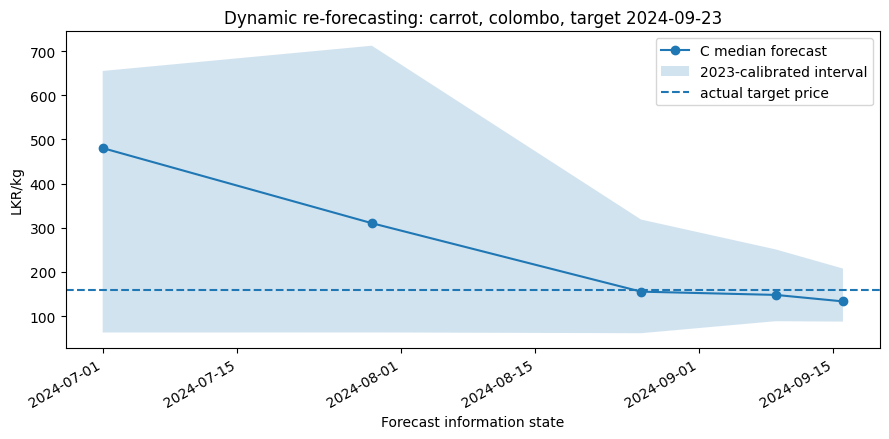

saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/inference/dynamic_reforecast_real_updates.csv
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/inference/dynamic_reforecast_real_updates.json
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/inference/dynamic_reforecast_real_updates.png
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/inference/dynamic_reforecast_saved_prediction_check.csv
✅ CELL 7 COMPLETE — Objective 5 demonstrated and every state verified against saved C predictions


In [7]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("======================================================")
print("REAL DYNAMIC CULTIVATION-UPDATE RE-FORECASTING")
print("======================================================")

C_DIR = NB1 / "experiment_c"

c_table = pd.read_parquet(
    C_DIR / "c_eligible_table.parquet"
)

for col in [
    "forecast_issue_week",
    "target_week",
    "cultivation_report_date",
]:
    c_table[col] = pd.to_datetime(
        c_table[col],
        format="mixed",
        errors="coerce",
    ).dt.normalize()

c_table["market_id"] = c_table[
    "market_id"
].map(normalize_market_id)

# ------------------------------------------------------------
# Find a test target with successive REAL report updates.
# ------------------------------------------------------------

search = c_table[
    c_table["split"].eq("test")
    & c_table["market_id"].isin(
        SCORE_MARKET_IDS
    )
    & c_table[
        "cultivation_progress_ratio_real"
    ].notna()
    & c_table[
        "cultivation_report_date"
    ].notna()
    & c_table[
        "forecast_horizon_weeks"
    ].isin(HORIZONS)
].copy()

groups = (
    search.groupby(
        [
            "crop_id",
            "market_id",
            "target_week",
        ],
        as_index=False,
    )
    .agg(
        information_states=(
            "forecast_issue_week",
            "nunique",
        ),
        distinct_real_reports=(
            "cultivation_report_date",
            "nunique",
        ),
        horizons=(
            "forecast_horizon_weeks",
            lambda x: ",".join(
                map(
                    str,
                    sorted(
                        set(
                            int(v)
                            for v in x
                        )
                    ),
                )
            ),
        ),
    )
)

candidates = groups[
    (groups["information_states"] >= 2)
    & (groups["distinct_real_reports"] >= 2)
].copy()

if candidates.empty:
    raise SystemExit(
        "No same-target test case with at least two different "
        "real cultivation report dates was found. "
        "Do not replace this with synthetic updates."
    )

# Prefer the case with the richest sequence of real updates.
choice = (
    candidates.sort_values(
        [
            "distinct_real_reports",
            "information_states",
            "target_week",
        ],
        ascending=[
            False,
            False,
            True,
        ],
    )
    .iloc[0]
)

crop = str(choice["crop_id"])
market = str(choice["market_id"])
target_week = pd.Timestamp(
    choice["target_week"]
)

states = search[
    search["crop_id"].astype(str).eq(crop)
    & search["market_id"].astype(str).eq(market)
    & search["target_week"].eq(target_week)
].copy()

# Keep one row per issue/horizon.
states = (
    states.sort_values(
        [
            "forecast_issue_week",
            "forecast_horizon_weeks",
        ]
    )
    .drop_duplicates(
        subset=[
            "forecast_issue_week",
            "forecast_horizon_weeks",
        ],
        keep="last",
    )
)

cqr = json.loads(
    (C_DIR / "cqr.json").read_text()
)

results = []

# ------------------------------------------------------------
# Predict each information state with its already-saved
# horizon-specific C model.
# ------------------------------------------------------------

for row_index, row in states.iterrows():
    horizon = int(
        row["forecast_horizon_weeks"]
    )

    subset = exact_training_subset(
        c_table,
        horizon,
    )

    if row_index not in subset.index:
        raise SystemExit(
            f"Chosen dynamic row {row_index} was not present "
            f"in the reconstructed h={horizon} eligible subset."
        )

    bundles = load_lgb_quantile_bundles(
        C_DIR / "models",
        "C",
        horizon,
    )

    columns = list(
        bundles["q50"]["columns"]
    )

    matrix = rebuild_design_matrix(
        subset,
        columns,
    )

    xrow = matrix.loc[
        [row_index]
    ].astype("float64")

    origin_price = float(
        row["last_observed_price_lkr_kg"]
    )

    raw_prices = {}

    for label, bundle in bundles.items():
        raw_logret = float(
            bundle["model"].predict(
                xrow
            )[0]
        )

        raw_prices[label] = max(
            0.01,
            origin_price
            * np.exp(raw_logret),
        )

    qhat = float(
        cqr[
            "qhat_by_model"
        ][
            "lightgbm"
        ][
            str(horizon)
        ]
    )

    lower = max(
        0.01,
        raw_prices["q05"] - qhat,
    )

    upper = (
        raw_prices["q95"]
        + qhat
    )

    actual = float(
        row["target_price_lkr_kg"]
    )

    median = float(
        raw_prices["q50"]
    )

    results.append({
        "crop": crop,
        "market": market,
        "target_week": target_week,
        "forecast_issue_week": pd.Timestamp(
            row["forecast_issue_week"]
        ),
        "horizon_weeks": horizon,
        "cultivation_report_date": pd.Timestamp(
            row["cultivation_report_date"]
        ),
        "cultivation_progress_ratio": float(
            row[
                "cultivation_progress_ratio_real"
            ]
        ),
        "target_exceeded": int(
            row[
                "cultivation_target_exceeded_real"
            ]
        ),
        "last_observed_price": origin_price,
        "lower_price": float(lower),
        "predicted_price": median,
        "upper_price": float(upper),
        "actual_price": actual,
        "absolute_error": abs(
            median - actual
        ),
        "interval_width": float(
            upper - lower
        ),
        "inside_interval": bool(
            lower <= actual <= upper
        ),
    })

dynamic = pd.DataFrame(results).sort_values(
    "forecast_issue_week"
).reset_index(drop=True)

# ------------------------------------------------------------
# Verify EVERY dynamic state against Notebook 1's already-saved
# predictions_c.csv.
#
# This proves the dynamic experiment is reproducing saved
# Experiment C predictions rather than generating a different
# inference path.
# ------------------------------------------------------------

saved_predictions = pd.read_csv(
    C_DIR / "predictions_c.csv"
)

for col in [
    "forecast_issue_week",
    "target_week",
]:
    saved_predictions[col] = pd.to_datetime(
        saved_predictions[col],
        format="mixed",
        errors="raise",
    ).dt.normalize()

saved_predictions["market_key"] = saved_predictions[
    "market"
].map(normalize_market_id)

saved_predictions["crop_key"] = (
    saved_predictions["crop"]
    .astype(str)
    .str.strip()
    .str.lower()
)

verification_rows = []

for row in dynamic.itertuples(index=False):
    match = saved_predictions[
        saved_predictions[
            "model"
        ].astype(str).str.lower().eq("lightgbm")
        & saved_predictions[
            "feature_set"
        ].astype(str).eq("C")
        & saved_predictions[
            "horizon"
        ].eq(int(row.horizon_weeks))
        & saved_predictions[
            "crop_key"
        ].eq(str(row.crop).strip().lower())
        & saved_predictions[
            "market_key"
        ].eq(normalize_market_id(row.market))
        & saved_predictions[
            "forecast_issue_week"
        ].eq(pd.Timestamp(row.forecast_issue_week))
        & saved_predictions[
            "target_week"
        ].eq(pd.Timestamp(row.target_week))
    ]

    if len(match) != 1:
        raise SystemExit(
            "❌ Dynamic saved-prediction lookup failed for "
            f"{row.crop}/{row.market}/"
            f"{pd.Timestamp(row.forecast_issue_week).date()}/"
            f"h={int(row.horizon_weeks)}: found {len(match)} rows."
        )

    saved_median = float(
        match["y_pred"].iloc[0]
    )

    absolute_difference = abs(
        saved_median
        - float(row.predicted_price)
    )

    verification_rows.append({
        "crop": row.crop,
        "market": row.market,
        "forecast_issue_week": row.forecast_issue_week,
        "target_week": row.target_week,
        "horizon_weeks": int(row.horizon_weeks),
        "dynamic_predicted_price": float(row.predicted_price),
        "saved_predicted_price": saved_median,
        "absolute_difference": absolute_difference,
    })

dynamic_verification = pd.DataFrame(
    verification_rows
)

MAX_ALLOWED_REPRODUCTION_DIFF = 1e-4

if (
    dynamic_verification[
        "absolute_difference"
    ].max()
    > MAX_ALLOWED_REPRODUCTION_DIFF
):
    print(
        dynamic_verification.to_string(
            index=False
        )
    )
    raise SystemExit(
        "❌ One or more dynamic states do not reproduce "
        "the saved Experiment C predictions."
    )

print(
    "✅ PASS: every dynamic information state reproduces "
    "the corresponding saved Experiment C prediction"
)

print(
    "Maximum dynamic reproduction difference:",
    dynamic_verification[
        "absolute_difference"
    ].max()
)

verification_path = (
    NB2
    / "inference"
    / "dynamic_reforecast_saved_prediction_check.csv"
)

dynamic_verification.to_csv(
    verification_path,
    index=False,
)

if dynamic[
    "actual_price"
].nunique() != 1:
    raise SystemExit(
        "The same-target re-forecast sequence does not have "
        "one unique actual future price."
    )

dynamic["new_real_report_since_previous_state"] = (
    dynamic[
        "cultivation_report_date"
    ]
    .ne(
        dynamic[
            "cultivation_report_date"
        ].shift(1)
    )
)

dynamic.loc[
    dynamic.index[0],
    "new_real_report_since_previous_state",
] = True

print(
    "Selected fixed target:",
    crop,
    market,
    str(
        target_week.date()
    ),
)

print(
    "Real information states:",
    len(dynamic),
)

print(
    "Distinct cultivation reports:",
    dynamic[
        "cultivation_report_date"
    ].nunique(),
)

display_cols = [
    "forecast_issue_week",
    "horizon_weeks",
    "cultivation_report_date",
    "cultivation_progress_ratio",
    "last_observed_price",
    "lower_price",
    "predicted_price",
    "upper_price",
    "actual_price",
    "absolute_error",
    "interval_width",
    "new_real_report_since_previous_state",
]

print(
    dynamic[
        display_cols
    ]
    .round(
        {
            "cultivation_progress_ratio": 4,
            "last_observed_price": 2,
            "lower_price": 2,
            "predicted_price": 2,
            "upper_price": 2,
            "actual_price": 2,
            "absolute_error": 2,
            "interval_width": 2,
        }
    )
    .to_string(
        index=False
    )
)

# ------------------------------------------------------------
# Save experiment table
# ------------------------------------------------------------

csv_path = (
    NB2
    / "inference"
    / "dynamic_reforecast_real_updates.csv"
)

dynamic.to_csv(
    csv_path,
    index=False,
)

json_path = (
    NB2
    / "inference"
    / "dynamic_reforecast_real_updates.json"
)

payload = {
    "experiment": "dynamic_cultivation_update_reforecast",
    "data_type": "real_national_cultivation_progress",
    "same_future_target": True,
    "models_retrained": False,
    "crop": crop,
    "market": market,
    "target_week": str(
        target_week.date()
    ),
    "states": (
        dynamic.assign(
            target_week=dynamic[
                "target_week"
            ].dt.strftime("%Y-%m-%d"),
            forecast_issue_week=dynamic[
                "forecast_issue_week"
            ].dt.strftime("%Y-%m-%d"),
            cultivation_report_date=dynamic[
                "cultivation_report_date"
            ].dt.strftime("%Y-%m-%d"),
        )
        .to_dict(
            orient="records"
        )
    ),
}

json_path.write_text(
    json.dumps(
        payload,
        indent=2,
    ),
    encoding="utf-8",
)

# ------------------------------------------------------------
# Plot: same target, forecasts through information states
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 4.5)
)

ax.plot(
    dynamic["forecast_issue_week"],
    dynamic["predicted_price"],
    marker="o",
    label="C median forecast",
)

ax.fill_between(
    dynamic["forecast_issue_week"],
    dynamic["lower_price"],
    dynamic["upper_price"],
    alpha=0.2,
    label="2023-calibrated interval",
)

ax.axhline(
    dynamic["actual_price"].iloc[0],
    linestyle="--",
    label="actual target price",
)

ax.set_title(
    f"Dynamic re-forecasting: {crop}, {market}, "
    f"target {target_week.date()}"
)

ax.set_xlabel(
    "Forecast information state"
)

ax.set_ylabel(
    "LKR/kg"
)

ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

plot_path = (
    NB2
    / "inference"
    / "dynamic_reforecast_real_updates.png"
)

fig.savefig(
    plot_path,
    dpi=130,
)

plt.show()

print("saved", csv_path)
print("saved", json_path)
print("saved", plot_path)
print("saved", verification_path)
print("✅ CELL 7 COMPLETE — Objective 5 demonstrated and every state verified against saved C predictions")


## Cell 8 — Supplementary sensitivity check using only observed national progress values

This is **not an additional accuracy result**.

It keeps one saved C forecast case fixed and substitutes low / median / high progress ratios taken from the real national DOA observations for that crop. This only demonstrates model responsiveness to the progress feature.

The empirical novelty evidence remains the B*→C ablation and the real same-target dynamic re-forecasting cell above.


In [8]:
import json
import joblib
import numpy as np
import pandas as pd

print("======================================================")
print("SUPPLEMENTARY C SENSITIVITY — OBSERVED VALUES ONLY")
print("======================================================")

audit = pd.read_csv(
    NB1
    / "audit"
    / "doa_cultivation_progress_audited.csv"
)

audit["crop"] = (
    audit["crop"]
    .astype(str)
    .str.strip()
    .str.lower()
)

audit["scope_level"] = (
    audit["scope_level"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

audit[
    "cultivation_progress_ratio"
] = pd.to_numeric(
    audit[
        "cultivation_progress_ratio"
    ],
    errors="coerce",
)

crop = str(
    c_example["crop"]
).strip().lower()

observed = (
    audit[
        audit["crop"].eq(crop)
        & audit["scope_level"].eq("national")
        & audit[
            "cultivation_progress_ratio"
        ].notna()
    ][
        "cultivation_progress_ratio"
    ]
    .astype(float)
)

if len(observed) < 3:
    raise SystemExit(
        "Not enough observed national ratios for the sensitivity check."
    )

ratios = {
    "observed_low_q25": float(
        observed.quantile(0.25)
    ),
    "observed_median": float(
        observed.quantile(0.50)
    ),
    "observed_high_q75": float(
        observed.quantile(0.75)
    ),
}

vector_base = dict(
    c_example["features"]
)

rows = []

for label, ratio in ratios.items():
    vector = dict(
        vector_base
    )

    vector[
        "cultivation_progress_ratio_real"
    ] = float(ratio)

    vector[
        "cultivation_target_exceeded_real"
    ] = int(
        ratio > 1.0
    )

    pred = predict_from_saved_vector(
        vector,
        c_example["origin_price"],
        c_bundles,
        c_qhat,
    )

    rows.append({
        "state": label,
        "observed_progress_ratio_used": ratio,
        "target_exceeded": int(
            ratio > 1.0
        ),
        "lower_price": pred["lower"],
        "predicted_price": pred["median"],
        "upper_price": pred["upper"],
    })

sensitivity = pd.DataFrame(
    rows
)

print(
    sensitivity.round(
        {
            "observed_progress_ratio_used": 4,
            "lower_price": 2,
            "predicted_price": 2,
            "upper_price": 2,
        }
    ).to_string(
        index=False
    )
)

out = (
    NB2
    / "runtime_demo"
    / "c_observed_ratio_sensitivity.csv"
)

sensitivity.to_csv(
    out,
    index=False,
)

note = (
    "This is a mechanism/sensitivity check using only "
    "observed national cultivation-progress ratios. "
    "It is not another held-out accuracy result."
)

(
    NB2
    / "runtime_demo"
    / "NOTE.txt"
).write_text(
    note,
    encoding="utf-8",
)

print(note)
print("saved", out)
print("✅ CELL 8 COMPLETE")


SUPPLEMENTARY C SENSITIVITY — OBSERVED VALUES ONLY
            state  observed_progress_ratio_used  target_exceeded  lower_price  predicted_price  upper_price
 observed_low_q25                        0.4147                0        61.17            173.7       271.86
  observed_median                        0.6831                0        60.01            173.7       268.93
observed_high_q75                        0.9732                0        60.01            173.7       270.11
This is a mechanism/sensitivity check using only observed national cultivation-progress ratios. It is not another held-out accuracy result.
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/runtime_demo/c_observed_ratio_sensitivity.csv
✅ CELL 8 COMPLETE


## Cell 9 — Create the 12 one-week saved-C forecasts

This produces one historical-demo one-week forecast for each of:

- 3 crops ×
- 4 headline score markets

using the already-saved C horizon-1 models.

The resulting packet contains the cultivation progress that the C model actually used.


In [9]:
import json
import joblib
import numpy as np
import pandas as pd

print("======================================================")
print("12 SAVED LIGHTGBM C ONE-WEEK FORECASTS")
print("======================================================")

C_DIR = NB1 / "experiment_c"

live = json.loads(
    (C_DIR / "live_vectors.json").read_text()
)

chosen = [
    item
    for item in live
    if int(item["horizon"]) == 1
]

if len(chosen) != 12:
    raise SystemExit(
        f"Expected 12 horizon-1 C vectors, found {len(chosen)}."
    )

bundles = load_lgb_quantile_bundles(
    C_DIR / "models",
    "C",
    1,
)

cqr = json.loads(
    (C_DIR / "cqr.json").read_text()
)

qhat = float(
    cqr[
        "qhat_by_model"
    ][
        "lightgbm"
    ][
        "1"
    ]
)

saved = pd.read_csv(
    C_DIR / "predictions_c.csv"
)

for col in [
    "forecast_issue_week",
    "target_week",
]:
    saved[col] = pd.to_datetime(
        saved[col],
        format="mixed",
        errors="raise",
    ).dt.normalize()

saved["market_key"] = saved[
    "market"
].map(normalize_market_id)

saved["crop_key"] = (
    saved["crop"]
    .astype(str)
    .str.strip()
    .str.lower()
)

forecasts = []
checks = []

for item in sorted(
    chosen,
    key=lambda value: (
        value["crop"],
        value["market"],
    ),
):
    crop = str(
        item["crop"]
    ).strip().lower()

    market = normalize_market_id(
        item["market"]
    )

    issue = pd.Timestamp(
        item["forecast_issue_week"]
    ).normalize()

    target = pd.Timestamp(
        item["target_week"]
    ).normalize()

    pred = predict_from_saved_vector(
        item["features"],
        item["origin_price"],
        bundles,
        qhat,
    )

    match = saved[
        saved[
            "model"
        ].astype(str).str.lower().eq("lightgbm")
        & saved[
            "feature_set"
        ].astype(str).eq("C")
        & saved[
            "horizon"
        ].eq(1)
        & saved[
            "crop_key"
        ].eq(crop)
        & saved[
            "market_key"
        ].eq(market)
        & saved[
            "forecast_issue_week"
        ].eq(issue)
        & saved[
            "target_week"
        ].eq(target)
    ]

    if len(match) != 1:
        raise SystemExit(
            f"Saved C row lookup failed for {crop}/{market}: "
            f"{len(match)} rows."
        )

    diff = abs(
        float(
            match["y_pred"].iloc[0]
        )
        - pred["median"]
    )

    if diff > 1e-4:
        raise SystemExit(
            f"Saved C reproduction failed for {crop}/{market}: {diff}"
        )

    checks.append({
        "crop": crop,
        "market": market,
        "absolute_difference": diff,
    })

    actual = float(
        item["y_true"]
    )

    forecasts.append({
        "crop": crop,
        "market": market,
        "forecast_issue_week": str(
            issue.date()
        ),
        "forecast_week": str(
            target.date()
        ),
        "horizon_weeks": 1,
        "cultivation_report_date": item[
            "cultivation_report_date"
        ],
        "cultivation_progress": float(
            item["real_progress_ratio"]
        ),
        "target_exceeded": int(
            item["real_target_exceeded"]
        ),
        "last_observed_price": round(
            float(
                item["origin_price"]
            ),
            2,
        ),
        "lower_price": round(
            pred["lower"],
            2,
        ),
        "predicted_price": round(
            pred["median"],
            2,
        ),
        "upper_price": round(
            pred["upper"],
            2,
        ),
        "actual_price_historical_demo": round(
            actual,
            2,
        ),
        "inside_interval_historical_demo": bool(
            pred["lower"]
            <= actual
            <= pred["upper"]
        ),
        "model": "lightgbm",
        "feature_set": "C",
        "model_version": "experiment_c",
    })

forecast_df = pd.DataFrame(
    forecasts
)

print(
    forecast_df[
        [
            "crop",
            "market",
            "forecast_issue_week",
            "forecast_week",
            "cultivation_progress",
            "lower_price",
            "predicted_price",
            "upper_price",
            "actual_price_historical_demo",
        ]
    ].to_string(
        index=False
    )
)

print(
    "max reproduction difference:",
    max(
        item[
            "absolute_difference"
        ]
        for item in checks
    ),
)

payload = {
    "horizon_weeks": 1,
    "model_version": "experiment_c",
    "feature_set": "C",
    "model": "lightgbm",
    "coverage_level_aim": 0.90,
    "spatial_scope_of_cultivation_progress": "national",
    "forecasts": forecasts,
}

json_path = (
    NB2
    / "inference"
    / "forecasts_12_c.json"
)

csv_path = (
    NB2
    / "inference"
    / "forecasts_12_c.csv"
)

check_path = (
    NB2
    / "inference"
    / "forecasts_12_c_reproduction_check.csv"
)

json_path.write_text(
    json.dumps(
        payload,
        indent=2,
    ),
    encoding="utf-8",
)

forecast_df.to_csv(
    csv_path,
    index=False,
)

pd.DataFrame(
    checks
).to_csv(
    check_path,
    index=False,
)

print("saved", json_path)
print("saved", csv_path)
print("✅ CELL 9 COMPLETE — all 12 C medians reproduced")


12 SAVED LIGHTGBM C ONE-WEEK FORECASTS
  crop       market forecast_issue_week forecast_week  cultivation_progress  lower_price  predicted_price  upper_price  actual_price_historical_demo
carrot      colombo          2025-09-29    2025-10-06              0.540000        69.24           107.44       167.51                        122.00
carrot     dambulla          2025-09-29    2025-10-06              0.540000        64.76           100.22       156.29                        136.00
carrot      meegoda          2025-09-29    2025-10-06              0.540000        84.16           134.26       209.17                        160.00
carrot nuwara_eliya          2025-09-29    2025-10-06              0.540000        80.56           126.70       197.42                        136.00
 leeks      colombo          2025-09-29    2025-10-06              0.579145        55.22            81.73       134.67                        131.67
 leeks     dambulla          2025-09-29    2025-10-06              

## Cell 10 — Packet for Member 3

This is the clean downstream contract for the crowding / viability component.

It sends:
- price median;
- lower/upper interval;
- intended interval level;
- measured C PICP by horizon;
- real cultivation progress used by the model;
- model version and feature set.

The historical actual price is deliberately removed from the downstream packet because a real deployment would not know the future actual.


In [10]:
import json
import pandas as pd

print("======================================================")
print("MEMBER 3 FORECAST PACKET")
print("======================================================")

c_metrics = pd.read_csv(
    NB1
    / "experiment_c"
    / "metrics_c.csv"
)

measured = {
    str(
        int(row.horizon)
    ): (
        None
        if pd.isna(
            row.picp_cqr
        )
        else float(
            row.picp_cqr
        )
    )
    for row in c_metrics[
        c_metrics[
            "model"
        ].astype(str).str.lower().eq(
            "lightgbm"
        )
    ].itertuples()
}

batch = json.loads(
    (
        NB2
        / "inference"
        / "forecasts_12_c.json"
    ).read_text()
)

downstream_forecasts = []

for item in batch["forecasts"]:
    downstream_forecasts.append({
        "crop": item["crop"],
        "market": item["market"],
        "forecast_issue_week": item[
            "forecast_issue_week"
        ],
        "forecast_week": item[
            "forecast_week"
        ],
        "horizon_weeks": item[
            "horizon_weeks"
        ],
        "predicted_price": item[
            "predicted_price"
        ],
        "lower_price": item[
            "lower_price"
        ],
        "upper_price": item[
            "upper_price"
        ],
        "coverage_level_aim": 0.90,
        "cultivation_progress": item[
            "cultivation_progress"
        ],
        "cultivation_report_date": item[
            "cultivation_report_date"
        ],
        "cultivation_progress_spatial_scope": "national",
        "model": "lightgbm",
        "model_version": "experiment_c",
        "feature_set": "C",
    })

packet = {
    "project": "J26-DS-322",
    "from_member": 2,
    "to_member": 3,
    "engine": "Hybrid Temporal Forecasting Engine",
    "purpose": (
        "Provide forward price forecasts and calibrated "
        "uncertainty to the downstream crowding / viability logic."
    ),
    "model_version": "experiment_c",
    "feature_set": "C",
    "cultivation_progress_spatial_scope": "national",
    "coverage_level_aim": 0.90,
    "coverage_level_note": (
        "0.90 is the intended interval level. "
        "Measured held-out PICP is supplied separately."
    ),
    "measured_picp_pct_by_horizon": measured,
    "experiment_c_status": C_STATUS.get(
        "status"
    ),
    "forecasts": downstream_forecasts,
}

path = (
    NB2
    / "inference"
    / "member3_forecast_c.json"
)

path.write_text(
    json.dumps(
        packet,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Measured LightGBM C calibrated PICP:",
    measured,
)

print(
    "Downstream forecasts:",
    len(
        downstream_forecasts
    ),
)

print(
    json.dumps(
        downstream_forecasts[0],
        indent=2,
    )
)

print("saved", path)
print("✅ CELL 10 COMPLETE")


MEMBER 3 FORECAST PACKET
Measured LightGBM C calibrated PICP: {'1': 85.71, '2': 91.29, '4': 91.17, '8': 93.74, '12': 93.56}
Downstream forecasts: 12
{
  "crop": "carrot",
  "market": "colombo",
  "forecast_issue_week": "2025-09-29",
  "forecast_week": "2025-10-06",
  "horizon_weeks": 1,
  "predicted_price": 107.44,
  "lower_price": 69.24,
  "upper_price": 167.51,
  "coverage_level_aim": 0.9,
  "cultivation_progress": 0.54,
  "cultivation_report_date": "2025-07-15",
  "cultivation_progress_spatial_scope": "national",
  "model": "lightgbm",
  "model_version": "experiment_c",
  "feature_set": "C"
}
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/inference/member3_forecast_c.json
✅ CELL 10 COMPLETE


## Cell 11 — Compact studio / Member 4 JSON outputs

These files summarize the final trained component for integration and presentation.

They are generated from saved Notebook 1 results and Notebook 2 inference outputs only.


In [11]:
import json
import pandas as pd

print("======================================================")
print("STUDIO / MEMBER 4 JSON")
print("======================================================")

studio = NB2 / "studio_json"

c_compare = pd.read_csv(
    NB1
    / "experiment_c"
    / "b_star_vs_c.csv"
)

c_metrics = pd.read_csv(
    NB1
    / "experiment_c"
    / "metrics_c.csv"
)

b_metrics = pd.read_csv(
    NB1
    / "experiment_b"
    / "metrics_with_cqr.csv"
)

fair = pd.read_csv(
    NB1
    / "evaluation"
    / "common_key_benchmark.csv"
)

dynamic_payload = json.loads(
    (
        NB2
        / "inference"
        / "dynamic_reforecast_real_updates.json"
    ).read_text()
)

batch_c = json.loads(
    (
        NB2
        / "inference"
        / "forecasts_12_c.json"
    ).read_text()
)

meta = {
    "project": "J26-DS-322",
    "member": "Garusingarachchi Y.B. — IT23415836",
    "component": "Hybrid Temporal Forecasting Engine",
    "panel_grain": "crop × market × week",
    "target": "weekly wholesale price, LKR/kg",
    "crops": [
        "carrot",
        "leeks",
        "tomato",
    ],
    "score_markets": [
        "Dambulla",
        "Colombo",
        "Meegoda",
        "Nuwara Eliya",
    ],
    "horizons_weeks": [
        1,
        2,
        4,
        8,
        12,
    ],
    "train": "issue weeks through 2022-12-31",
    "calibration": "2023",
    "test": "2024-2025",
    "tree_selection_validation": "2022 internal training slice",
    "conformal_calibration": "untouched 2023 block",
    "experiment_c": {
        "trained": bool(
            C_STATUS.get(
                "experiment_c_trained"
            )
        ),
        "status": C_STATUS.get(
            "status"
        ),
        "spatial_scope": "national",
        "exact_season_matching": True,
        "season_identity_source": "official DOA source season label/year",
        "report_age_cutoff_days": None,
        "district_rows_used_for_scoring": False,
        "no_synthetic_values": True,
    },
}

evaluation = {
    "experiment_b": b_metrics.to_dict(
        orient="records"
    ),
    "experiment_c": c_metrics.to_dict(
        orient="records"
    ),
    "fair_common_key_benchmark": fair.to_dict(
        orient="records"
    ),
}

ablation = {
    "definition": {
        "A": "price lags + seasonality",
        "B": "A + supply-origin weather + macro variables + finished-season historical extent",
        "B_star": "B retrained on exactly the real-C eligible rows",
        "C": "B + real national within-season cultivation progress",
    },
    "b_star_vs_c": c_compare.to_dict(
        orient="records"
    ),
    "interpretation": (
        "Negative error-change percentage means C reduced error "
        "relative to B* on identical rows."
    ),
}

models = {
    "primary_novelty_model": "LightGBM quantile",
    "robustness_model": "XGBoost quantile",
    "classical_baseline": "SARIMAX (1,1,1) x (1,0,0,52)",
    "quantiles": [
        0.05,
        0.50,
        0.95,
    ],
    "interval_calibration": (
        "Chronological conformal calibration on 2023 only after ordered interval projection around unchanged q50"
    ),
}

importance = {
    "status": "computed_in_notebook1",
    "model": "LightGBM C median",
    "horizon_weeks": 4,
    "method": "SHAP TreeExplainer",
    "rows": evaluation_package[
        "shap"
    ].to_dict(
        orient="records"
    ),
    "note": (
        "SHAP is supporting explainability evidence. "
        "The B* versus C ablation is the novelty test."
    ),
}


final_evaluation_package = {
    "point_forecast_benchmark": evaluation_package[
        "benchmark"
    ].to_dict(
        orient="records"
    ),
    "best_point_model_by_horizon": evaluation_package[
        "best_point"
    ].to_dict(
        orient="records"
    ),
    "seasonal_naive_common_subset": evaluation_package[
        "seasonal_naive"
    ].to_dict(
        orient="records"
    ),
    "model_vs_naive_bootstrap": evaluation_package[
        "model_vs_naive_bootstrap"
    ].to_dict(
        orient="records"
    ),
    "probabilistic_evaluation_c": evaluation_package[
        "probabilistic_c"
    ].to_dict(
        orient="records"
    ),
    "quantile_crossing_diagnostic_c": evaluation_package[
        "quantile_crossing"
    ].to_dict(
        orient="records"
    ),
    "conditional_interval_evaluation_c": evaluation_package[
        "conditional_intervals"
    ].to_dict(
        orient="records"
    ),
    "feature_set_evolution": evaluation_package[
        "feature_evolution"
    ].to_dict(
        orient="records"
    ),
    "bstar_vs_c_bootstrap": evaluation_package[
        "novelty_bootstrap"
    ].to_dict(
        orient="records"
    ),
    "robustness_c_h4_by_crop": evaluation_package[
        "robustness_crop"
    ].to_dict(
        orient="records"
    ),
    "robustness_c_h4_by_market": evaluation_package[
        "robustness_market"
    ].to_dict(
        orient="records"
    ),
    "robustness_c_h4_by_season": evaluation_package[
        "robustness_season"
    ].to_dict(
        orient="records"
    ),
    "robustness_c_h4_shock_vs_nonshock": evaluation_package[
        "robustness_shock_c"
    ].to_dict(
        orient="records"
    ),
    "robustness_b_h4_shock_vs_nonshock": evaluation_package[
        "robustness_shock_b"
    ].to_dict(
        orient="records"
    ),
    "residual_summary_c_h4": evaluation_package[
        "residual"
    ].to_dict(
        orient="records"
    ),
    "shap_top_features_h4_c": evaluation_package[
        "shap"
    ].head(20).to_dict(
        orient="records"
    ),
}

outputs = {
    "meta.json": meta,
    "evaluation.json": evaluation,
    "final_evaluation_package.json": final_evaluation_package,
    "ablation.json": ablation,
    "models.json": models,
    "importance.json": importance,
    "experiment_c.json": {
        "status": C_STATUS,
        "comparison": c_compare.to_dict(
            orient="records"
        ),
        "dynamic_reforecast": dynamic_payload,
    },
    "live_forecast.json": batch_c,
}

for filename, payload in outputs.items():
    path = studio / filename

    path.write_text(
        json.dumps(
            payload,
            indent=2,
            default=str,
        ),
        encoding="utf-8",
    )

    print("saved", path)

print("✅ CELL 11 COMPLETE")


STUDIO / MEMBER 4 JSON
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/studio_json/meta.json
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/studio_json/evaluation.json
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/studio_json/final_evaluation_package.json
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/studio_json/ablation.json
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/studio_json/models.json
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/studio_json/importance.json
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/studio_json/experiment_c.json
saved /content/drive/MyDrive/DS322-member2/02_from_notebook2/studio_json/live_forecast.json
✅ CELL 11 COMPLETE


## Cell 12 — Final Notebook 2 manifest and completion checks

This cell verifies the outputs expected from the completed Member 2 workflow.

It also confirms once more that Notebook 2 performed inference only.


In [12]:
from pathlib import Path
import pandas as pd

print("======================================================")
print("NOTEBOOK 2 FINAL CHECK")
print("======================================================")

required = [
    "inference/research_result_summary.csv",
    "inference/saved_b_example.json",
    "inference/saved_c_example.json",
    "inference/dynamic_reforecast_real_updates.csv",
    "inference/dynamic_reforecast_real_updates.json",
    "inference/dynamic_reforecast_real_updates.png",
    "inference/dynamic_reforecast_saved_prediction_check.csv",
    "inference/forecasts_12_c.json",
    "inference/forecasts_12_c.csv",
    "inference/forecasts_12_c_reproduction_check.csv",
    "inference/member3_forecast_c.json",
    "runtime_demo/c_observed_ratio_sensitivity.csv",
    "runtime_demo/NOTE.txt",
    "studio_json/meta.json",
    "studio_json/evaluation.json",
    "studio_json/final_evaluation_package.json",
    "studio_json/ablation.json",
    "studio_json/models.json",
    "studio_json/importance.json",
    "studio_json/experiment_c.json",
    "studio_json/live_forecast.json",
]

missing = [
    name
    for name in required
    if not (NB2 / name).is_file()
]

if missing:
    print("Missing Notebook 2 outputs:")
    for name in missing:
        print(" -", name)
    raise SystemExit(
        "Notebook 2 is not complete."
    )

rows = []

for path in sorted(
    NB2.rglob("*")
):
    if (
        path.is_file()
        and path.name
        != "manifest.csv"
    ):
        rows.append({
            "path": str(
                path.relative_to(
                    NB2
                )
            ),
            "bytes": path.stat().st_size,
        })

manifest = pd.DataFrame(
    rows
)

manifest_path = (
    NB2
    / "manifest.csv"
)

manifest.to_csv(
    manifest_path,
    index=False,
)

print(
    manifest.to_string(
        index=False
    )
)

print("\nRESEARCH COMPLETION CHECK")
print("PASS saved A/B results read without fitting")
print("PASS saved C forecast reproduced")
print("PASS real same-target dynamic re-forecast experiment created")
print("PASS every dynamic state verified against saved Experiment C predictions")
print("PASS 12 C forecasts created for 3 crops × 4 score markets")
print("PASS Member 3 packet created")
print("PASS studio JSON files created")
print("PASS no synthetic cultivation-progress accuracy result created")
print("PASS final forecasting evaluation package carried forward from Notebook 1")
print("PASS no classification-only evaluation is used")
print("PASS official DOA source-season identity is carried from Notebook 1")
print("PASS saved-model intervals use the same ordered projection as Notebook 1")
print("PASS Notebook 2 contains no model training step")

print("\nsaved", manifest_path)
print("\n✅ NOTEBOOK 2 COMPLETE")
print("Do not refit models in Notebook 2.")


NOTEBOOK 2 FINAL CHECK
                                                   path  bytes
          inference/dynamic_reforecast_real_updates.csv   1201
         inference/dynamic_reforecast_real_updates.json   3548
          inference/dynamic_reforecast_real_updates.png  70669
inference/dynamic_reforecast_saved_prediction_check.csv    524
                           inference/forecasts_12_c.csv   1809
                          inference/forecasts_12_c.json   7408
        inference/forecasts_12_c_reproduction_check.csv    349
                      inference/member3_forecast_c.json   7079
                  inference/research_result_summary.csv    672
                         inference/saved_b_example.json    376
                         inference/saved_c_example.json    485
                                  runtime_demo/NOTE.txt    139
          runtime_demo/c_observed_ratio_sensitivity.csv    372
                              studio_json/ablation.json  13210
                            stud